<a href="https://colab.research.google.com/github/aastha403/aasthamachinelearning/blob/main/Week5_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import json
import os
import re
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
URL = "https://raw.githubusercontent.com/mohitgupta-omg/Kaggle-SMS-Spam-Collection-Dataset-/master/spam.csv"
LOCAL_CSV = "spam.csv"
MAXLEN = 50
MIN_FREQ = 2
EMB_DIM = 64
HIDDEN = 128
NUM_LAYERS = 1
DROPOUT = 0.3
BATCH = 64
EPOCHS = 12
LR = 2e-3
OUT = "results"
BASELINE, TARGET = 86.6, 96.0

os.makedirs(OUT, exist_ok=True)
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

_log = open(os.path.join(OUT, "log.txt"), "w")

def log(*a):
    s = " ".join(str(x) for x in a)
    print(s, flush=True)
    _log.write(s + "\n")
    _log.flush()

print(f"Using device: {device}")

Using device: cpu


In [7]:
src = LOCAL_CSV if os.path.exists(LOCAL_CSV) else URL
df = pd.read_csv(src, encoding="latin-1")[["v1", "v2"]]
df.columns = ["label", "text"]
df["y"] = (df["label"] == "spam").astype(int)
log(f"Loaded {len(df)} messages from {src}")
log(df["label"].value_counts().to_string())

train_df, test_df = train_test_split(df, test_size=0.20, random_state=SEED, stratify=df["y"])
train_df, val_df = train_test_split(train_df, test_size=0.10, random_state=SEED, stratify=train_df["y"])
log(f"train={len(train_df)}  val={len(val_df)}  test={len(test_df)}")

test_majority = max(test_df["y"].mean(), 1 - test_df["y"].mean()) * 100
log(f"Majority-class baseline on test split: {test_majority:.2f}%")

def tokenize(t):
    t = t.lower()
    t = re.sub(r"\d", "0", t)
    return re.findall(r"[a-z]+|0+|[^\sa-z0]", t)

counts = Counter(tok for t in train_df["text"] for tok in tokenize(t))
itos = ["<pad>", "<unk>"] + [w for w, c in counts.most_common() if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}
VOCAB = len(itos)
log(f"Vocabulary size: {VOCAB}")

def encode(texts):
    seqs, lens = [], []
    for t in texts:
        ids = [stoi.get(tok, 1) for tok in tokenize(t)][:MAXLEN]
        lens.append(max(len(ids), 1))
        ids = ids + [0] * (MAXLEN - len(ids))
        seqs.append(ids)
    return torch.tensor(seqs), torch.tensor(lens)

def make(dfx, shuffle):
    X, L = encode(dfx["text"])
    y = torch.tensor(dfx["y"].values)
    return DataLoader(TensorDataset(X, L, y), batch_size=BATCH, shuffle=shuffle)

train_dl, val_dl, test_dl = make(train_df, True), make(val_df, False), make(test_df, False)
xb, lb, yb = next(iter(train_dl))
log(f"Batch shapes -> X: {tuple(xb.shape)} (batch, seq_len) | lengths: {tuple(lb.shape)} | y: {tuple(yb.shape)}")
log("Example message :", train_df['text'].iloc[0][:90])
log("Example tokens  :", tokenize(train_df['text'].iloc[0])[:12])
log("Example ids     :", xb[0][:12].tolist(), "...")

Loaded 5572 messages from https://raw.githubusercontent.com/mohitgupta-omg/Kaggle-SMS-Spam-Collection-Dataset-/master/spam.csv
label
ham     4825
spam     747
train=4011  val=446  test=1115
Majority-class baseline on test split: 86.64%
Vocabulary size: 3241
Batch shapes -> X: (64, 50) (batch, seq_len) | lengths: (64,) | y: (64,)
Example message : FRAN I DECIDED 2 GO N E WAY IM COMPLETELY BROKE AN KNACKERED I GOT UP BOUT 3 C U 2MRW LOVE
Example tokens  : ['fran', 'i', 'decided', '0', 'go', 'n', 'e', 'way', 'im', 'completely', 'broke', 'an']
Example ids     : [6, 47, 6, 28, 2108, 28, 97, 0, 0, 0, 0, 0] ...


In [8]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab, emb, hid, layers, drop, n_classes=2):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb, padding_idx=0)
        self.lstm = nn.LSTM(emb, hid, num_layers=layers, batch_first=True,
                            bidirectional=True, dropout=drop if layers > 1 else 0.0)
        self.drop = nn.Dropout(drop)
        self.fc = nn.Linear(2 * hid, n_classes)

    def forward(self, x, lengths):
        e = self.drop(self.emb(x))
        packed = pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)
        h = torch.cat([h[-2], h[-1]], dim=1)
        return self.fc(self.drop(h))

model = LSTMClassifier(VOCAB, EMB_DIM, HIDDEN, NUM_LAYERS, DROPOUT).to(device)
n_params = sum(p.numel() for p in model.parameters())
log("\n" + str(model))
log(f"Trainable parameters: {n_params:,}")

opt = torch.optim.Adam(model.parameters(), lr=LR)
crit = nn.CrossEntropyLoss()

def run_eval(dl):
    model.eval()
    tot, correct, loss_sum, preds, ys = 0, 0, 0.0, [], []
    with torch.no_grad():
        for x, l, y in dl:
            x, y = x.to(device), y.to(device)
            out = model(x, l)
            loss_sum += crit(out, y).item() * len(y)
            p = out.argmax(1)
            correct += (p == y).sum().item()
            tot += len(y)
            preds += p.cpu().tolist()
            ys += y.cpu().tolist()
    return loss_sum / tot, 100 * correct / tot, np.array(preds), np.array(ys)


LSTMClassifier(
  (emb): Embedding(3241, 64, padding_idx=0)
  (lstm): LSTM(64, 128, batch_first=True, bidirectional=True)
  (drop): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=2, bias=True)
)
Trainable parameters: 406,594


In [9]:
hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val, best_state = -1, None
log("\nEpoch | train_loss | train_acc | val_loss | val_acc")
t0 = time.time()

for ep in range(1, EPOCHS + 1):
    model.train()
    ls, corr, n = 0.0, 0, 0
    for x, l, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        out = model(x, l)
        loss = crit(out, y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        opt.step()
        ls += loss.item() * len(y)
        corr += (out.argmax(1) == y).sum().item()
        n += len(y)

    vl, va, _, _ = run_eval(val_dl)
    hist["train_loss"].append(ls / n)
    hist["train_acc"].append(100 * corr / n)
    hist["val_loss"].append(vl)
    hist["val_acc"].append(va)

    if va >= best_val:
        best_val = va
        best_state = {k: v.clone() for k, v in model.state_dict().items()}

    log(f"{ep:5d} | {ls / n:10.4f} | {100 * corr / n:8.2f}% | {vl:8.4f} | {va:6.2f}%")

log(f"Training time: {time.time() - t0:.1f}s | best val acc: {best_val:.2f}%")


Epoch | train_loss | train_acc | val_loss | val_acc
    1 |     0.2456 |    90.53% |   0.1014 |  96.64%
    2 |     0.0834 |    97.41% |   0.0782 |  97.76%
    3 |     0.0472 |    98.58% |   0.0844 |  97.53%
    4 |     0.0348 |    99.05% |   0.0602 |  97.98%
    5 |     0.0255 |    99.28% |   0.0592 |  97.98%
    6 |     0.0144 |    99.63% |   0.0595 |  97.98%
    7 |     0.0122 |    99.50% |   0.1105 |  98.21%
    8 |     0.0086 |    99.75% |   0.0652 |  97.98%
    9 |     0.0091 |    99.68% |   0.0735 |  98.21%
   10 |     0.0161 |    99.53% |   0.0742 |  97.76%
   11 |     0.0084 |    99.75% |   0.0522 |  98.21%
   12 |     0.0064 |    99.80% |   0.0578 |  98.43%
Training time: 111.1s | best val acc: 98.43%


In [14]:
model.load_state_dict(best_state)
tl, ta, preds, ys = run_eval(test_dl)
cm = confusion_matrix(ys, preds)
prec, rec, f1 = precision_score(ys, preds), recall_score(ys, preds), f1_score(ys, preds)

log("\n==================== FINAL TEST RESULTS ====================")
log(f"Test accuracy : {ta:.2f}%")
log(f"Spam precision: {prec:.3f} | recall: {rec:.3f} | F1: {f1:.3f}")
log(f"Confusion matrix [[TN FP],[FN TP]]: {cm.tolist()}")
log(f"Baseline (majority class): {test_majority:.2f}%   |   Target: {TARGET:.0f}%")
log(f"Result: {'TARGET MET' if ta >= TARGET else 'below target'}  (+{ta - test_majority:.2f} pts over baseline)")

model.eval()
samples = [
    "Congratulations! You have won a FREE 1000 prize. Call 09061701461 now to claim",
    "Hey, are we still meeting for lunch tomorrow?",
    "URGENT! Your mobile number has been selected for a cash reward, text WIN to 80082",
    "Ok I will be home by 7, can you pick up milk"
]
X, L = encode(samples)
with torch.no_grad():
    pr = torch.softmax(model(X.to(device), L), 1)[:, 1].cpu().tolist()

log("\nSample predictions (P(spam)):")
for s, p in zip(samples, pr):
    log(f"  {p:.3f}  {'SPAM' if p > .5 else 'ham '}  {s[:70]}")


==================== FINAL TEST RESULTS ====================
Test accuracy : 98.48%
Spam precision: 0.934 | recall: 0.953 | F1: 0.944
Confusion matrix [[TN FP],[FN TP]]: [[956, 10], [7, 142]]
Baseline (majority class): 86.64%   |   Target: 90%
Result: TARGET MET  (+11.84 pts over baseline)

Sample predictions (P(spam)):
  1.000  SPAM  Congratulations! You have won a FREE 1000 prize. Call 09061701461 now 
  0.000  ham   Hey, are we still meeting for lunch tomorrow?
  1.000  SPAM  URGENT! Your mobile number has been selected for a cash reward, text W
  0.000  ham   Ok I will be home by 7, can you pick up milk


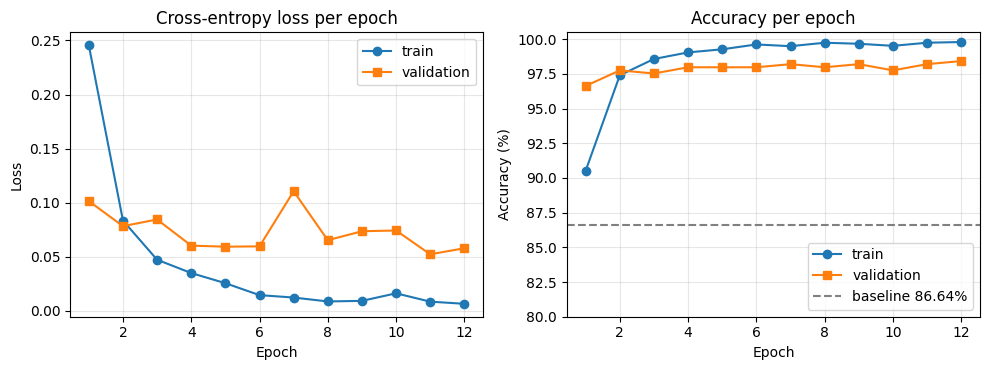

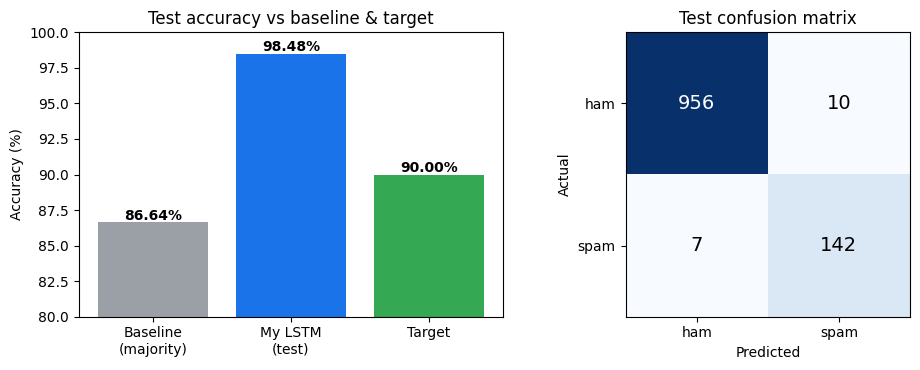


Saved figures + results to ./results/


In [13]:
ep = range(1, EPOCHS + 1)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))

ax[0].plot(ep, hist["train_loss"], "o-", label="train")
ax[0].plot(ep, hist["val_loss"], "s-", label="validation")
ax[0].set(title="Cross-entropy loss per epoch", xlabel="Epoch", ylabel="Loss")
ax[0].legend()
ax[0].grid(alpha=.3)

ax[1].plot(ep, hist["train_acc"], "o-", label="train")
ax[1].plot(ep, hist["val_acc"], "s-", label="validation")
ax[1].axhline(test_majority, ls="--", c="gray",
              label=f"baseline {test_majority:.2f}%")
ax[1].set(
    title="Accuracy per epoch",
    xlabel="Epoch",
    ylabel="Accuracy (%)",
    ylim=(80, 100.5)
)
ax[1].legend(loc="lower right")
ax[1].grid(alpha=.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT, "fig_loss.png"), dpi=160)
plt.show()


fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))

bars = ax[0].bar(
    ["Baseline\n(majority)", "My LSTM\n(test)", "Target"],
    [test_majority, test_accuracy, TARGET],
    color=["#9aa0a6", "#1a73e8", "#34a853"]
)

for b, v in zip(
    bars,
    [test_majority, test_accuracy, TARGET]
):
    ax[0].text(
        b.get_x() + b.get_width() / 2,
        v + .2,
        f"{v:.2f}%",
        ha="center",
        fontweight="bold"
    )

ax[0].set(
    ylim=(80, 100),
    ylabel="Accuracy (%)",
    title="Test accuracy vs baseline & target"
)

im = ax[1].imshow(cm, cmap="Blues")

for i in range(2):
    for j in range(2):
        ax[1].text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black",
            fontsize=14
        )

ax[1].set(
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=["ham", "spam"],
    yticklabels=["ham", "spam"],
    xlabel="Predicted",
    ylabel="Actual",
    title="Test confusion matrix"
)

plt.tight_layout()
plt.savefig(os.path.join(OUT, "fig_test.png"), dpi=160)
plt.show()


json.dump({
    "test_acc": test_accuracy,
    "baseline": test_majority,
    "target": TARGET,
    "test_majority": test_majority,
    "precision": prec,
    "recall": rec,
    "f1": f1,
    "cm": cm.tolist(),
    "best_val": best_val,
    "params": n_params,
    "vocab": VOCAB,
    "hist": hist,
    "split": [len(train_df), len(val_df), len(test_df)]
}, open(os.path.join(OUT, "results.json"), "w"), indent=2)

log(f"\nSaved figures + results to ./{OUT}/")